# Прогнозирование температуры звезды с помощью нейронной сети

**Цель работы:** построить нейронную сеть для прогнозирования температуры поверхности звезды в Кельвинах по её наблюдаемым и классификационным характеристикам.

В базе обсерватории есть характеристики уже изученных 240 звёзд:
* Относительная светимость `L/Lo` — светимость звезды относительно Солнца.
* Относительный радиус `R/Ro` — радиус звезды относительно радиуса Солнца.
* Абсолютная звёздная величина `Mv` — физическая величина, характеризующая блеск звезды.
* Звёздный цвет `Star color` (white, red, blue, yellow, yellow-orange и др.) — цвет звезды, который определяют на основе спектрального анализа.
* Тип звезды `Star type`: Коричневый карлик	- 0, Красный карлик - 1, Белый карлик - 2, Звёзды главной последовательности - 3, Сверхгигант - 4, Гипергигант - 5.
* Абсолютная температура `Temperature(K)` — температура на поверхности звезды в Кельвинах.

**План работы**
1. Загрузка данных
2. Предобработка и анализ данных
3. Построение базовой нейронной сети
4. Улучшение нейронной сети
5. Оценка качества и анализ ошибок 
6. Выводы

## Загрузка данных

In [1]:
!pip install phik -q

In [2]:
# Импортируем необходимые библиотеки
import os
import pandas as pd
import random
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from phik import phik_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import itertools

In [3]:
# Для воспроизводимости результатов
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.use_deterministic_algorithms(True)

In [4]:
# Загружаем исходные данные из файла
data_path = '6_class.csv'

if os.path.exists(data_path):
    df = pd.read_csv('6_class.csv')
else:
    raise FileNotFoundError(
        f'Файл с данными не найден: {data_path}'
    )

In [5]:
# Первые строки датафрейма
df.head(5)

,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,0,3068,0.002400,0.1700,16.12,0,Red
1,1,3042,0.000500,0.1542,16.60,0,Red
2,2,2600,0.000300,0.1020,18.70,0,Red
3,3,2800,0.000200,0.1600,16.65,0,Red
4,4,1939,0.000138,0.1030,20.06,0,Red


In [6]:
# Общая информация
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              240 non-null    int64  
 1   Temperature (K)         240 non-null    int64  
 2   Luminosity(L/Lo)        240 non-null    float64
 3   Radius(R/Ro)            240 non-null    float64
 4   Absolute magnitude(Mv)  240 non-null    float64
 5   Star type               240 non-null    int64  
 6   Star color              240 non-null    object 
dtypes: float64(3), int64(3), object(1)
memory usage: 13.3+ KB


В наборе данных содержится информация о 240 звёздах. Кроме служебного столбца `Unnamed: 0` доступны пять входных признаков и целевая переменная `Temperature (K)`.

Числовыми признаками являются относительная светимость, относительный радиус и абсолютная звёздная величина. `Star color` и `Star type` являются категориальными признаками; при этом `Star type` хранится в виде числовых кодов 0–5.

Пропущенные значения отсутствуют. Целевая переменная содержит температуру поверхности звезды в Кельвинах.

## Предобработка и анализ данных

### Предобработка данных

Можно удалить первый столбец из датафрейма, т.к. он не содержит полезной информации.

In [7]:
df = df.drop('Unnamed: 0', axis=1)
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,3068,0.002400,0.1700,16.12,0,Red
1,3042,0.000500,0.1542,16.60,0,Red
2,2600,0.000300,0.1020,18.70,0,Red
3,2800,0.000200,0.1600,16.65,0,Red
4,1939,0.000138,0.1030,20.06,0,Red


Проверим пропуски, полные дубликаты и корректность категориальных значений.

In [8]:
# Выводим количество пропусков в датафрейме
print(f'В датафрейме {df.isna().sum().sum()} пропусков')

В датафрейме 0 пропусков


In [9]:
# Выводим количество явных дубликатов в датафрейме
print(f'В датафрейме {df.duplicated().sum()} дубликатов')

В датафрейме 0 дубликатов


In [10]:
# Выводим уникальные значения столбца `Star color`
df['Star color'].unique()

array(['Red', 'Blue White', 'White', 'Yellowish White', 'Blue white',
       'Pale yellow orange', 'Blue', 'Blue-white', 'Whitish',
       'yellow-white', 'Orange', 'White-Yellow', 'white', 'Blue ',
       'yellowish', 'Yellowish', 'Orange-Red', 'Blue white ',
       'Blue-White'], dtype=object)

Из-за разных форматов записи возникают неявные дубликаты. Приведем записи к единообразию: переведем в нижний регистр, удалим пробелы в начале и конце, заменим пробелы в остальных случаях на дефис.

In [11]:
df['Star color'] = df['Star color'].str.lower().str.strip().str.replace(r'\s+', '-', regex=True)

In [12]:
df['Star color'] = df['Star color'].replace(['yellow-white'],'white-yellow')
df['Star color'].unique()

array(['red', 'blue-white', 'white', 'yellowish-white',
       'pale-yellow-orange', 'blue', 'whitish', 'white-yellow', 'orange',
       'yellowish', 'orange-red'], dtype=object)

In [13]:
df['Star color'].value_counts()

Star color
red                   112
blue                   56
blue-white             41
white                  10
white-yellow            9
yellowish-white         3
yellowish               3
whitish                 2
orange                  2
pale-yellow-orange      1
orange-red              1
Name: count, dtype: int64

После унификации написания в признаке `Star color` осталось 11 категорий. Некоторые близкие по смыслу варианты встречаются крайне редко: от одного до трёх наблюдений. При объёме выборки всего 240 объектов такие категории могут привести к появлению очень редких признаков после One-Hot Encoding и нестабильности модели при разделении данных на обучающую и тестовую выборки. Кроме того, согласно основной (гарвардской) спектральной классификации звезд имеется 7 основных цветов: blue, blue-white, white, white-yellow, yellow, orange, red.

Поэтому близкие варианты названий объединим в более общие категории.

In [14]:
color_mapping = {
    'yellowish-white': 'white-yellow',
    'yellowish': 'yellow',
    'pale-yellow-orange': 'orange',
    'orange-red': 'orange',
    'whitish': 'white'
}

df['Star color'] = df['Star color'].replace(color_mapping)

In [15]:
# Выводим уникальные значения столбца `Star color` после преобразований
df['Star color'].unique()

array(['red', 'blue-white', 'white', 'white-yellow', 'orange', 'blue',
       'yellow'], dtype=object)

После объединения осталось 7 категорий Star color. Преобразование уменьшило число крайне редких категорий и разреженность признакового пространств

Перейдем к исследовательскому анализу данных.


### Исследовательский анализ данных

In [16]:
# Cтатистика для числовых столбцов
num_columns = ['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']

df[num_columns].describe()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv)
count,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396
std,9552.425037,179432.244940,517.155763,10.532512
min,1939.000000,0.000080,0.008400,-11.920000
25%,3344.250000,0.000865,0.102750,-6.232500
50%,5776.000000,0.070500,0.762500,8.313000
75%,15055.500000,198050.000000,42.750000,13.697500
max,40000.000000,849420.000000,1948.500000,20.060000


Для всех количественных данных среднее значение отличается от медианы, изучим эти данные подробнее, построив графики.

In [17]:
# Функция для построения гистограммы и диаграммы размаха для количественных признаков
def hist_and_boxplot(x, df, bins):
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1) 
    sns.histplot(data=df, x=x, bins=bins, kde=True)
    plt.title('Гистограмма')
    plt.subplot(1, 2, 2) 
    df.boxplot(column=x)
    plt.title('Диаграмма размаха')
    plt.suptitle(x, fontsize=15)
    plt.show()

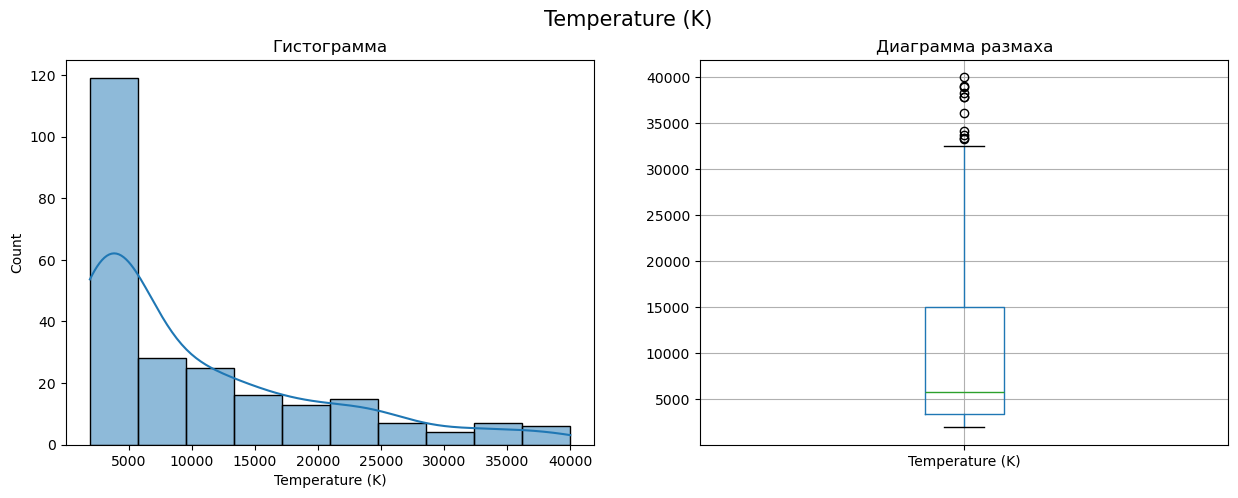

In [18]:
hist_and_boxplot('Temperature (K)', df, 10)

Температура поверхности звёзд варьируется от 1939 до 40.000 K. Распределение имеет правую асимметрию: медиана составляет 5.776 K, а 75% наблюдений имеют температуру не выше примерно 15.056 K.

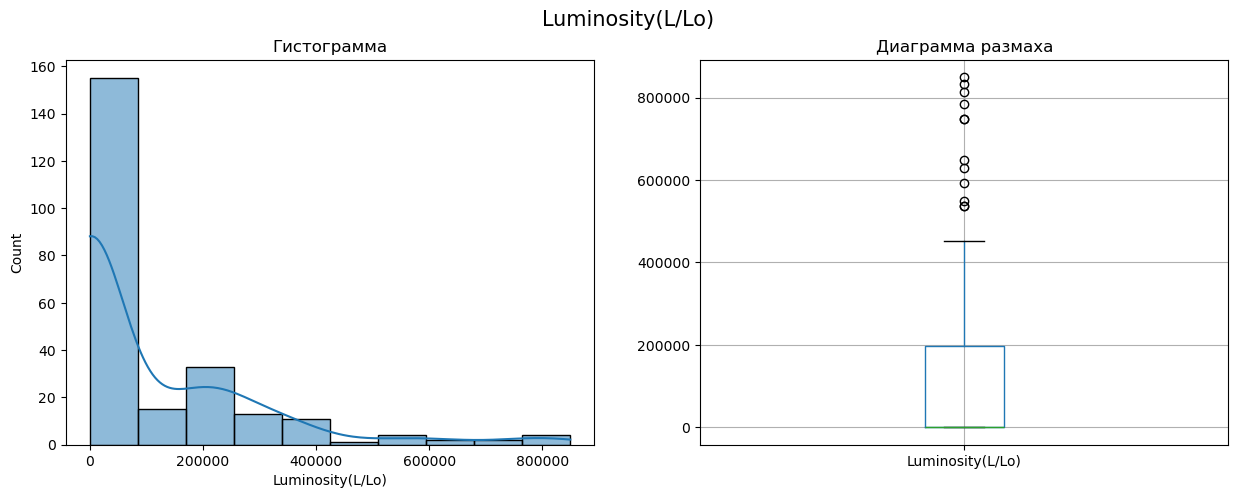

In [19]:
hist_and_boxplot('Luminosity(L/Lo)', df, 10)

Относительная светимость изменяется в очень широком диапазоне - `от 0.00008 до 849420 L/Lo`. Минимальное значение примерно в 12.500 раз ниже светимости Солнца, тогда как максимальное превышает её почти в 850 тысяч раз. Медиана составляет `0.0705 L/Lo`, что указывает на сильную правую асимметрию распределения.

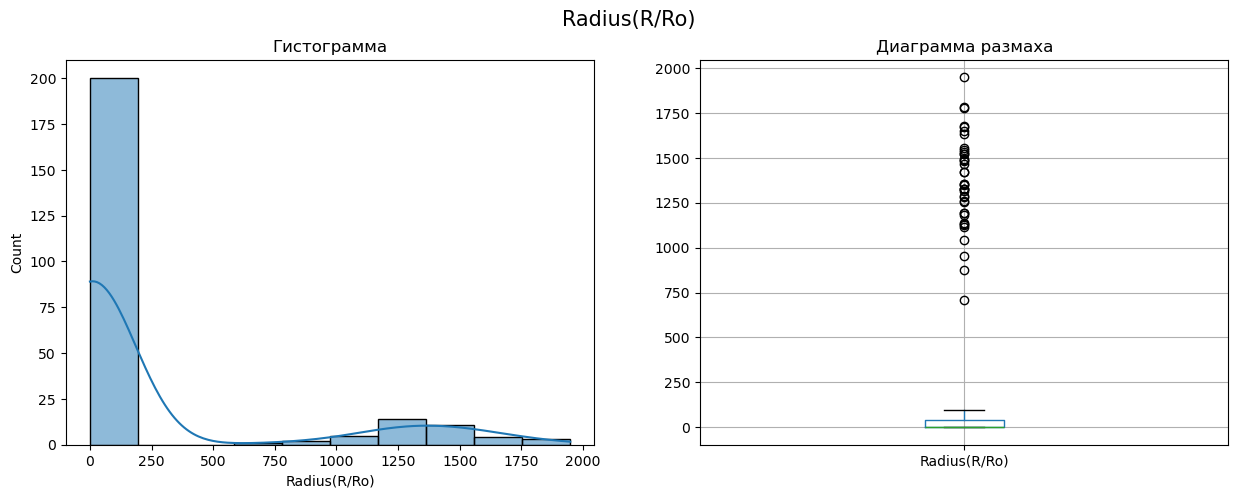

In [20]:
hist_and_boxplot('Radius(R/Ro)', df, 10)

Относительный радиус варьируется от `0.0084 до 1948.5 R/Ro`. Минимальный радиус примерно в 119 раз меньше солнечного, максимальный - почти в 1950 раз больше. Медиана составляет `0.7625 R/Ro`. Распределение сильно неоднородно и содержит группы объектов с существенно различающимися масштабами радиуса.

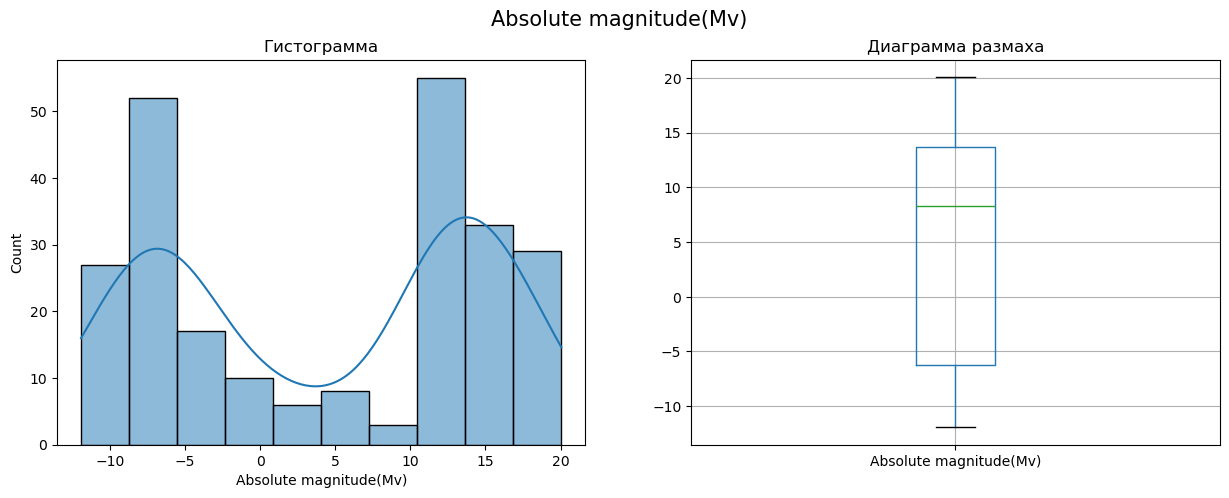

In [21]:
hist_and_boxplot('Absolute magnitude(Mv)', df, 10)

Абсолютная звёздная величина варьируется от −11.92 до 20.06. Распределение имеет выраженную многомодальную структуру: заметны группы объектов с отрицательными и высокими положительными значениями. Такое распределение может быть связано с присутствием в выборке различных типов звёзд.

В столбце `Star type` хранится информация о типе звезды, это категориальные данные.

In [22]:
# Функция для построения столбчатой диаграммы для категориальных признаков
def count_plot(x, df):
    sns.countplot(
        x=x,
        data=df, 
        hue=x,
        palette='Set3',
        edgecolor='black',
        legend=False
    )
    plt.tight_layout() 
    plt.show()

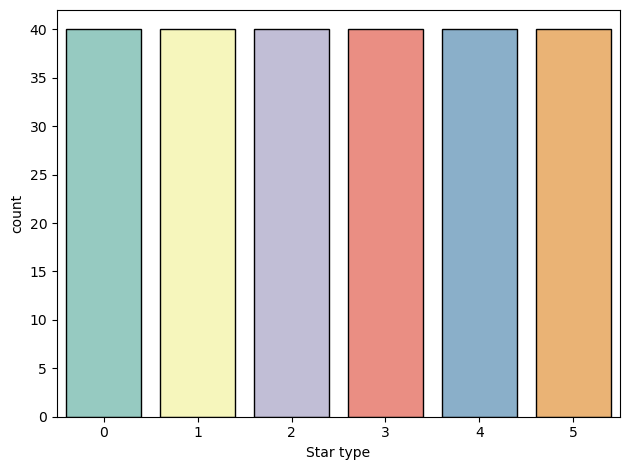

In [23]:
count_plot('Star type', df)

Каждый из шести типов представлен ровно 40 объектами. Следовательно, выборка сбалансирована по `Star typ`e; такое распределение, вероятно, является особенностью формирования датасета.

In [24]:
# Функция для построения столбчатой диаграммы для категориальных признаков с сортировкой
def count_plot_sort(y, df):
    order = df[y].value_counts(ascending=False).index   # сортировка по убыванию
    sns.countplot(
        y=y,
        order=order,
        data=df, 
        hue=y,
        palette='Set3',
        edgecolor='black',
        legend=False
    )
    plt.tight_layout() 
    plt.show()

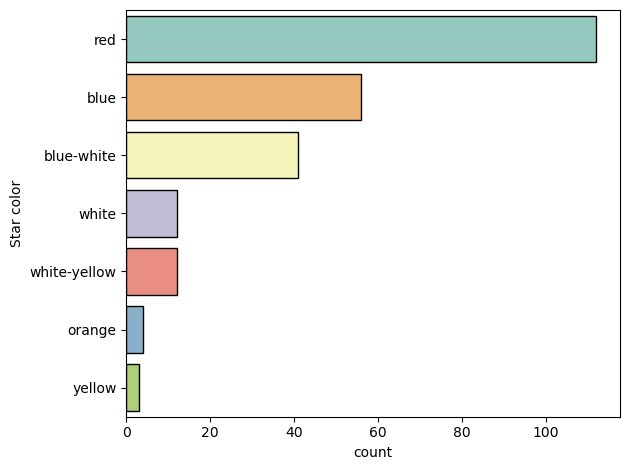

In [25]:
count_plot_sort('Star color', df)

После унификации написания и объединения редких близких категорий осталось 7 значений `Star color`. В выборке преобладают красные звёзды; также широко представлены синие и бело-синие. Остальные категории встречаются существенно реже.

### Корреляционный анализ данных

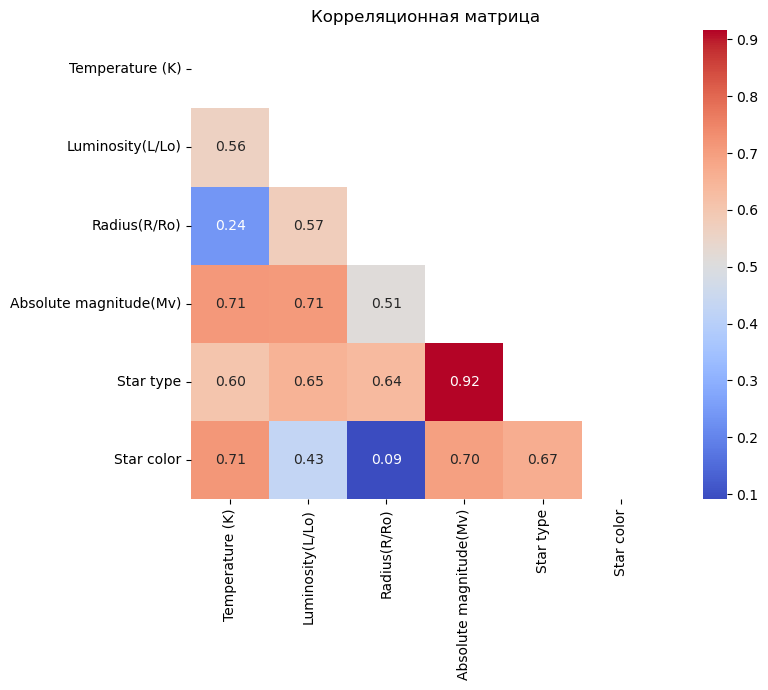

In [26]:
phik_matrix = df.phik_matrix(interval_cols=['Temperature (K)','Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)'])

mask = np.triu(np.ones_like(phik_matrix, dtype=bool))
plt.figure(figsize=(10, 7))
sns.heatmap(
    phik_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    mask=mask,
    square=True
)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

Наиболее выраженные связи целевой переменной `Temperature (K)` наблюдаются с `Absolute magnitude(Mv)` и `Star color`. Среди входных признаков также присутствуют заметные взаимосвязи, в частности между `Absolute magnitude(Mv)` и `Star type`.

Чтобы подробнее рассмотреть связь температуры поверхности звезды с числовыми признаками, построим диаграммы рассеяния с разделением объектов по `Star type`.
Значения относительной светимости `Luminosity(L/Lo)` и радиуса `Radius(R/Ro)` изменяются на несколько порядков, поэтому на линейной шкале значительная часть наблюдений оказывается визуально сжата около нуля. Для этих двух признаков используем логарифмическую шкалу по оси y. Для `Absolute magnitude(Mv)` сохраним линейную шкалу, поскольку диапазон этого признака значительно компактнее и включает отрицательные значения.

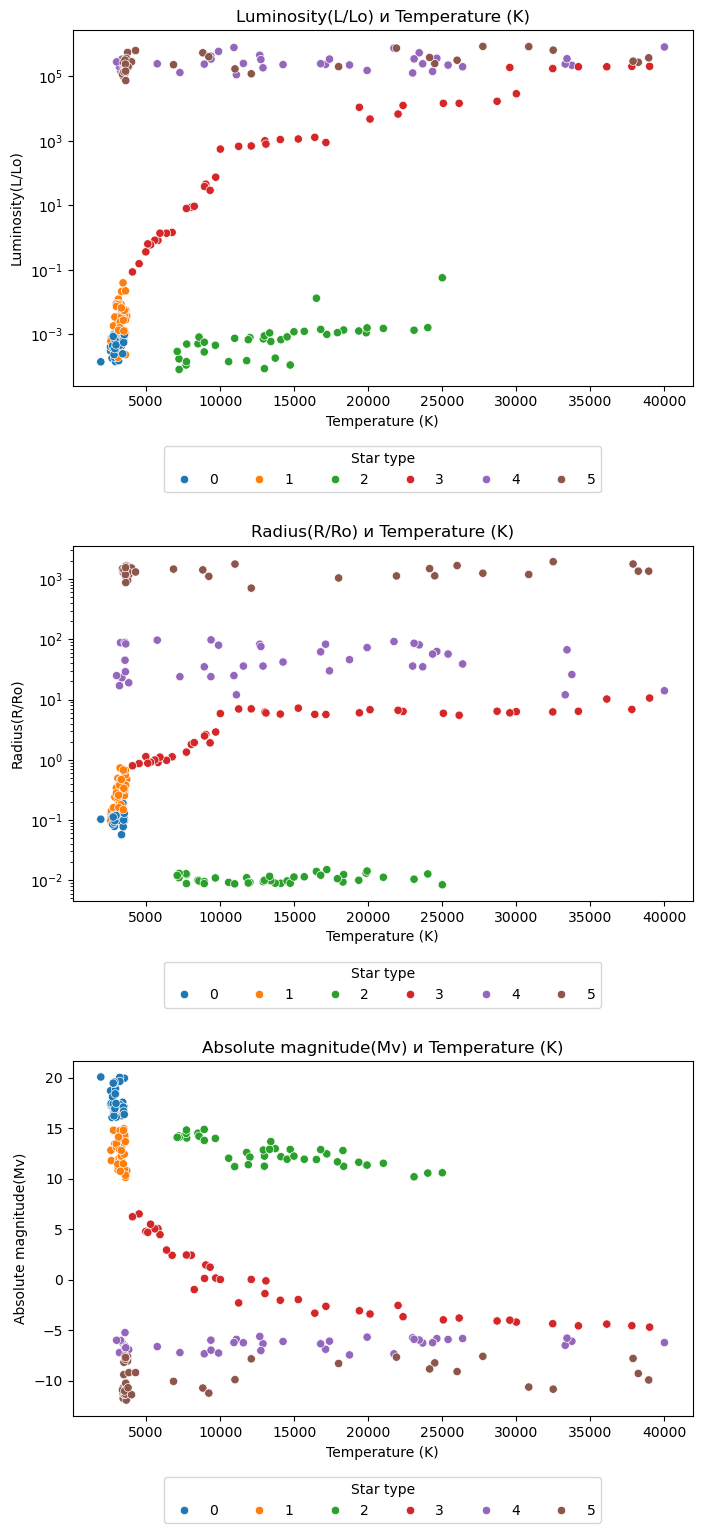

In [27]:
cols = ['Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']

fig, axes = plt.subplots(3, 1, figsize=(8, 18))
fig.subplots_adjust(hspace=0.45)

for i, col in enumerate(cols):
    sns.scatterplot(
        data=df,
        x='Temperature (K)',
        y=col,
        hue='Star type',
        palette='tab10',
        ax=axes[i]
    )

    # Для светимости и радиуса используем логарифмическую шкалу
    if col in ['Luminosity(L/Lo)', 'Radius(R/Ro)']:
        axes[i].set_yscale('log')

    axes[i].set_xlabel('Temperature (K)')
    axes[i].set_ylabel(col)
    axes[i].set_title(f'{col} и Temperature (K)')

    axes[i].legend(
        title='Star type',
        loc='lower center',
        bbox_to_anchor=(0.5, -0.32),
        ncol=6
    )

plt.show()

На графиках различные значения `Star type` образуют хорошо различимые области по абсолютной звёздной величине, температуре, радиусу и светимости. О

Звёзды в наборе данных разделены на шесть типов: коричневый карлик — 0, красный карлик — 1, белый карлик — 2, звезда главной последовательности — 3, сверхгигант — 4, гипергигант — 5.

В имеющейся выборке наблюдаются следующие закономерности:
* Абсолютная звёздная величина `Absolute magnitude(Mv)` у объектов типов 0–2 положительная и в основном превышает 10.
* У звёзд главной последовательности абсолютная звёздная величина преимущественно находится примерно в диапазоне от −5 до 5; с ростом температуры на графике наблюдается тенденция к её уменьшению.
* У сверхгигантов и гипергигантов (типы 4–5) абсолютная звёздная величина отрицательная и преимущественно ниже −5.
* Сверхгиганты и гипергиганты занимают близкие диапазоны светимости, однако заметно различаются по радиусу; гипергиганты в выборке в целом имеют существенно большие размеры.
* Коричневые и красные карлики (типы 0–1) имеют температуру ниже примерно 5000 K, а их радиусы и светимости меньше солнечных.
* Температура белых карликов (тип 2) в выборке составляет примерно от 10 000 до 25 000 K.
* Звёзды главной последовательности, сверхгиганты и гипергиганты представлены в широком диапазоне температур.

**Выводы по результатам предобработки и анализа данных**

1. Удалён служебный столбец Unnamed: 0, не содержащий полезной информации для моделирования.
2. Пропущенные значения и полные дубликаты не обнаружены. Для `Star color` унифицированы варианты написания и объединены несколько редких близких категорий.
3. Числовые признаки имеют сильно неоднородные распределения и большой диапазон значений. Экстремальные значения светимости и радиуса не удалялись автоматически, поскольку в рамках данного набора данных они соответствуют различным типам звёзд и не выглядят как очевидные ошибки данных.
4. `Star type` представлен шестью категориями по 40 объектов в каждой; таким образом, выборка искусственно сбалансирована по этому признаку.
5. `Star color` распределён неравномерно: большую часть выборки составляют красные, синие и бело-синие звёзды.
6. Анализ матрицы корреляции показывает выраженные связи температуры с `Star color` и `Absolute magnitude(Mv)`, а также взаимосвязи между некоторыми входными признаками.

## Построение базовой нейронной сети

### Подготовка данных к построению модели

In [28]:
X = df.drop(columns='Temperature (K)')
y = df['Temperature (K)']

# Отделяем финальную тестовую выборку
X_train_val_raw, X_test_raw, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=X['Star color']
)

# Делим оставшиеся данные на train и validation
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val_raw,
    y_train_val,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=X_train_val_raw['Star color']
)

In [29]:
print(f'Размерность обучающей выборки до обработки: {X_train_raw.shape}')
print(f'Размерность валидационной выборки до обработки: {X_val_raw.shape}')
print(f'Размерность тестовой выборки до обработки: {X_test_raw.shape}')

Размерность обучающей выборки до обработки: (153, 5)
Размерность валидационной выборки до обработки: (39, 5)
Размерность тестовой выборки до обработки: (48, 5)


Категоризируем исходные данные, а также проведем масштабирование количественных данных.

In [30]:
numerical_cols = ['Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']
categorical_cols = ['Star type', 'Star color']

# Создаем трансформер
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            'num',
            StandardScaler(),
            numerical_cols
        )
    ]
)

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

In [31]:
print(f'Размерность обучающей выборки после обработки: {X_train.shape}')
print(f'Размерность валидационной выборки после обработки: {X_val.shape}')
print(f'Размерность тестовой выборки после обработки: {X_test.shape}')

Размерность обучающей выборки после обработки: (153, 16)
Размерность валидационной выборки после обработки: (39, 16)
Размерность тестовой выборки после обработки: (48, 16)


### Построение базовой модели

In [32]:
# Создаем тензоры
X_train = torch.FloatTensor(np.asarray(X_train))
X_val = torch.FloatTensor(np.asarray(X_val))
X_test = torch.FloatTensor(np.asarray(X_test))

y_train = torch.FloatTensor(y_train.to_numpy())
y_val = torch.FloatTensor(y_val.to_numpy())
y_test = torch.FloatTensor(y_test.to_numpy())

Создадим класс для задания архитектуры нейронной сети. В базовой архитектуре используем два полносвязных скрытых слоя и функцию активации `ReLU`. Выходной слой содержит один нейрон без дополнительной функции активации, поскольку решается задача регрессии и модель должна прогнозировать непрерывное значение температуры.

In [33]:
class NeuralNet(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons, activation_fn=nn.ReLU):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.act1 = activation_fn()
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.act2 = activation_fn()
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.fc2(x)
        x = self.act2(x)
        x = self.fc3(x)
        return x

В качестве параметров будут: model, optimizer, а также обучающие и валидационные выборки.

In [34]:
def neural_net(model, optimizer, X_train, y_train, X_val, y_val):
    num_epochs = 8000
    loss_fn = nn.MSELoss()

    best_rmse = float('inf')
    best_epoch = 0
    best_model_state = None

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        preds = model(X_train).flatten()
        mse_loss = loss_fn(preds, y_train)

        mse_loss.backward()
        optimizer.step()

        if epoch % 50 == 0:
            model.eval()

            with torch.no_grad():
                val_preds = model(X_val).flatten()
                val_mse = loss_fn(val_preds, y_val)
                val_rmse = torch.sqrt(val_mse).item()

            if val_rmse < best_rmse:
                best_rmse = val_rmse
                best_epoch = epoch
                best_model_state = copy.deepcopy(model.state_dict())

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return best_rmse, best_epoch, model

В качестве базовой модели используем нейронную сеть с двумя скрытыми слоями по 8 и 4 нейрона и функцией активации `ReLU`. Для оптимизации используем Adam с `learning_rate=0.01`. Модель обучается на обучающей выборке, а лучшая эпоха выбирается по минимальному `RMSE` на валидационной выборке.

Количество нейронов на входном и выходном слоях будет фиксированным:

- n_in_neurons = X_train.shape[1] — количество входных признаков после преобразования;
- n_out_neurons = 1 — один прогнозируемый показатель температуры.

Количество нейронов на скрытых слоях можно варьировать. Дополнительно сравним функции активации `ReLU`, `ELU` и `LeakyReLU`. 

In [35]:
# Список конфигураций скрытых слоев для перебора
hidden_configs = [
    [8, 4],
    [10, 6],
    [12, 8]
]

# Список функций активации для перебора
activation_functions = [
    nn.ReLU,
    nn.ELU,
    nn.LeakyReLU
]

In [36]:
best_val_rmse = float('inf')
best_config = None
best_activation_fn = None
best_arch_model = None
best_arch_epoch = None

architecture_results = []

for hidden_sizes in hidden_configs:
    for activation_fn in activation_functions:
        torch.manual_seed(42)

        n_hidden_1, n_hidden_2 = hidden_sizes

        model = NeuralNet(
            n_in_neurons=X_train.shape[1],
            n_hidden_neurons_1=n_hidden_1,
            n_hidden_neurons_2=n_hidden_2,
            n_out_neurons=1,
            activation_fn=activation_fn
        )

        optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

        val_rmse, epoch, trained_model = neural_net(model, optimizer, X_train, y_train, X_val, y_val)

        activation_name = activation_fn.__name__

        architecture_results.append({
            'hidden_layers': hidden_sizes,
            'activation': activation_name,
            'val_rmse': val_rmse,
            'epoch': epoch
        })

        print(
            f'{str(hidden_sizes):<12} '
            f'{activation_name:<12} '
            f'Val RMSE = {val_rmse:<10.2f} '
            f'epoch = {epoch}'
        )

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_config = hidden_sizes
            best_activation_fn = activation_fn
            best_arch_model = trained_model
            best_arch_epoch = epoch

print('\nЛУЧШАЯ АРХИТЕКТУРА')
print(f'Скрытые слои: {best_config}')
print(f'Функция активации: {best_activation_fn.__name__}')
print(f'Val RMSE: {best_val_rmse:.2f} K')
print(f'Лучшая эпоха: {best_arch_epoch}')

[8, 4]       ReLU         Val RMSE = 4883.41    epoch = 1600
[8, 4]       ELU          Val RMSE = 4127.45    epoch = 5450
[8, 4]       LeakyReLU    Val RMSE = 4496.29    epoch = 2300
[10, 6]      ReLU         Val RMSE = 4886.84    epoch = 1600
[10, 6]      ELU          Val RMSE = 4787.69    epoch = 1200
[10, 6]      LeakyReLU    Val RMSE = 4701.23    epoch = 1600
[12, 8]      ReLU         Val RMSE = 4805.46    epoch = 1600
[12, 8]      ELU          Val RMSE = 4497.38    epoch = 800
[12, 8]      LeakyReLU    Val RMSE = 4601.72    epoch = 1150

ЛУЧШАЯ АРХИТЕКТУРА
Скрытые слои: [8, 4]
Функция активации: ELU
Val RMSE: 4127.45 K
Лучшая эпоха: 5450


Среди рассмотренных архитектур лучший результат показала сеть с двумя скрытыми слоями [8, 4] и функцией активации `ELU`. `RMSE` составил 4127.45 K. Для исходной конфигурации [8,4] + `ReLU` `RMSE` составлял 4883.41 K, поэтому подбор функции активации позволил снизить ошибку примерно на 756 K.

Архитектуру [8,4] + `ELU` зафиксируем как baseline и далее не будем изменять количество слоёв, нейронов и функцию активации.

### График «Факт — Прогноз»

Создадим функцию для визуализации качества, где по горизонтальной оси будут отложены условные номера звёзд, а по вертикальной - температура в Кельвинах.

In [37]:
def fact_prediction(predictions, y_true, title='Model'):
    y_pred = predictions.detach().cpu().numpy().reshape(-1)
    y_true = y_true.detach().cpu().numpy().reshape(-1)

    x = np.arange(len(y_pred))

    fig, ax = plt.subplots(figsize=(15, 8))

    ax.bar(x, y_true, width=0.6, alpha=0.8, color='skyblue',  label='Факт')
    ax.bar(x, y_pred, width=0.3, alpha=0.8, color='gold',  label='Прогноз')

    ax.set_xlabel('Номер звезды')
    ax.set_ylabel('Температура, K')
    ax.set_title(title, fontsize=16)
    ax.legend()
    ax.grid(alpha=0.1)

    plt.show()

Построим график для модели с лучшей метрикой качества из полученных. 

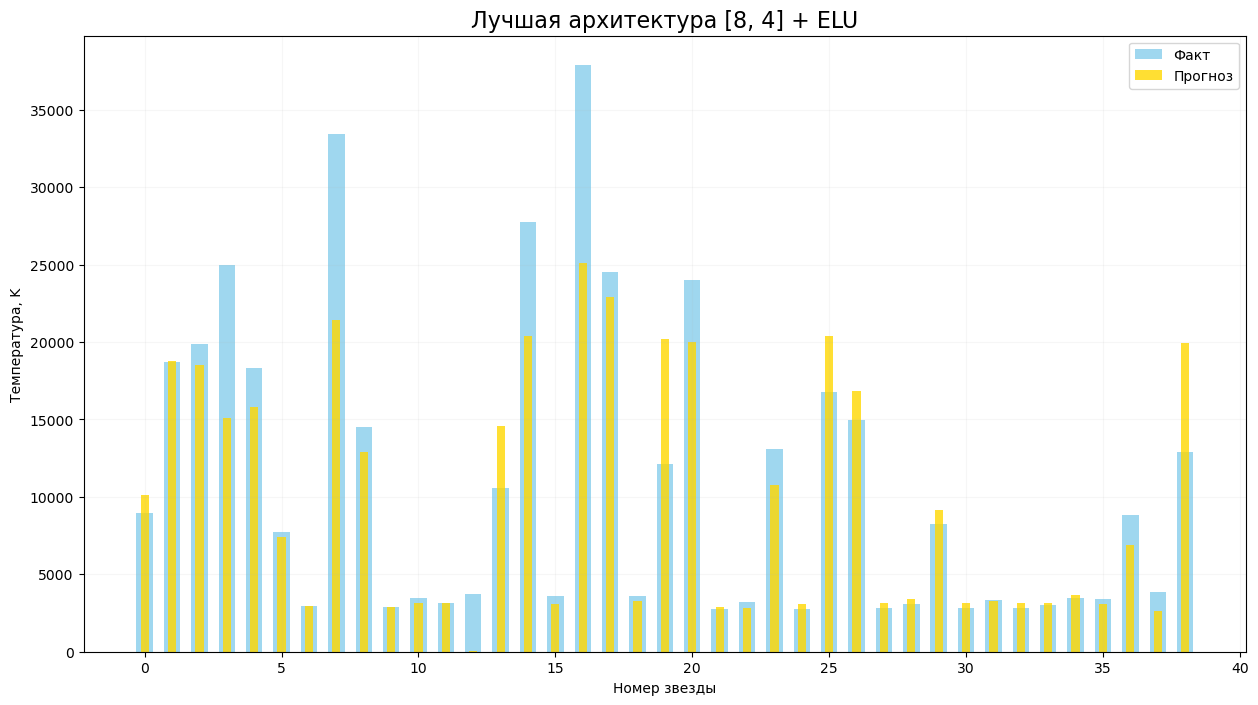

In [38]:
best_arch_model.eval()

with torch.no_grad():
    val_predictions = best_arch_model(X_val).flatten()

# Построим график
fact_prediction(val_predictions, y_val,'Лучшая архитектура [8, 4] + ELU')

**Выводы**

На графике видно, что для многих объектов с температурой до 5000 K прогнозы близки к фактическим значениям, тогда как среди более горячих звёзд встречаются более крупные абсолютные ошибки. 

## Улучшение нейронной сети

В предыдущем разделе лучшее качество на валидационной выборке показала нейронная сеть с двумя скрытыми слоями по 8 и 4 нейронов и функцией активации ELU: `RMSE = 4127.45 K` на валидационной выборке.

Попробуем улучшить качество этой модели, изменяя схему обучения и добавляя методы регуляризации. Проверим использование `Batch Normalization`, а затем исследуем влияние `Dropout` и размера батча. Все варианты будем сравнивать по `RMSE` на валидационной выборке; тестовая выборка до окончательного выбора модели не используется.

### Batch Normalization

Добавим Batch Normalization после каждого полносвязного скрытого слоя и до функции активации `ELU`. 

In [39]:
class NetWithBN(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons):
        super(NetWithBN, self).__init__()

        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.bn1 = nn.BatchNorm1d(n_hidden_neurons_1)    # добавляем BN
        self.act1 = nn.ELU()

        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.bn2 = nn.BatchNorm1d(n_hidden_neurons_2)   # добавляем BN
        self.act2 = nn.ELU()

        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)   # используем BN
        x = self.act1(x)

        x = self.fc2(x)
        x = self.bn2(x)   # используем BN
        x = self.act2(x)

        x = self.fc3(x)  
        return x

In [40]:
torch.manual_seed(42)

model_BN = NetWithBN(
    n_in_neurons=X_train.shape[1],
    n_hidden_neurons_1=8,
    n_hidden_neurons_2=4,
    n_out_neurons=1
)

optimizer_BN = torch.optim.Adam(model_BN.parameters(), lr=1e-2)

best_rmse_BN, best_epoch_BN, model_BN = neural_net(model_BN, optimizer_BN, X_train, y_train, X_val, y_val)

print(f'Batch Normalization: Val RMSE = {best_rmse_BN:.2f} K, лучшая эпоха = {best_epoch_BN}')

Batch Normalization: Val RMSE = 7142.47 K, лучшая эпоха = 6450


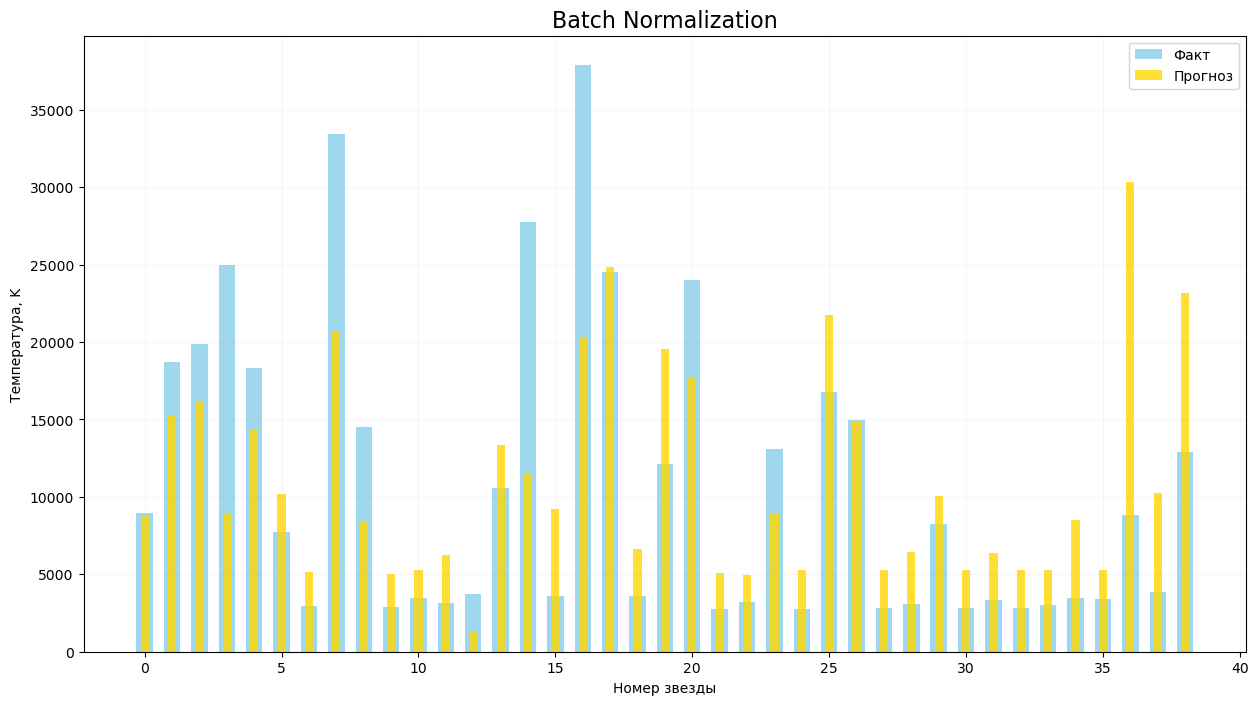

In [41]:
model_BN.eval()

with torch.no_grad():
    val_predictions_BN = model_BN(X_val).flatten()

fact_prediction(val_predictions_BN, y_val, 'Batch Normalization')

Добавление `Batch Normalization` к выбранной архитектуре [8,4] + `ELU` не улучшило качество модели. `RMSE` увеличился с 4127.45 K до 7142.47 K. Поэтому `Batch Normalization` исключается из дальнейших экспериментов.

На графике «Факт-прогноз» также видно, что для модель с `Batch Normalization` начинает плохо предсказывать и для объектов с поверхностной температурой < 5 тысяч К. 

### Dropout + batch size

Проверим, улучшит ли качество модели использование Dropout совместно с обучением по мини-батчам. Архитектуру [8, 4] и функцию активации ELU оставим без изменений. Будем перебирать вероятность отключения нейронов p и размер батча, выбирая лучшую конфигурацию по RMSE на валидационной выборке.

In [42]:
class NetWithDropout(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_out_neurons, p=0.1):
        super(NetWithDropout, self).__init__()
        
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.act1 = nn.ELU()
        self.dropout1 = nn.Dropout(p)   # добавляем Dropout
        
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.act2 = nn.ELU()
        self.dropout2 = nn.Dropout(p)   # добавляем Dropout
        
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_out_neurons)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.dropout1(x)   # используем dropout
        
        x = self.fc2(x)
        x = self.act2(x)
        x = self.dropout2(x)   # используем dropout
        
        x = self.fc3(x) 
        return x

Создадим функцию для обучения нейронной сети c заданным размером батча.

In [43]:
def neural_net_with_batch_size(model, optimizer, X_train, y_train, X_val, y_val, batch_size):
    num_epochs = 8000
    loss_fn = nn.MSELoss()

    best_rmse = float('inf')
    best_epoch = 0
    best_model_state = None

    dataset = TensorDataset(X_train, y_train)

    generator = torch.Generator()
    generator.manual_seed(42)

    train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=generator)

    for epoch in range(num_epochs):
        model.train()

        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()

            preds = model(batch_X).flatten()
            mse_loss = loss_fn(preds, batch_y)

            mse_loss.backward()
            optimizer.step()

        if epoch % 50 == 0:
            model.eval()

            with torch.no_grad():
                val_preds = model(X_val).flatten()
                val_mse = loss_fn(val_preds, y_val)
                val_rmse = torch.sqrt(val_mse).item()

            if val_rmse < best_rmse:
                best_rmse = val_rmse
                best_epoch = epoch
                best_model_state = copy.deepcopy(model.state_dict())

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return best_rmse, best_epoch, model

In [44]:
# Список размеров батча для перебора
batch_sizes = [4, 8, 16, 32]
# Список dropout для перебора
dropouts = [0.0, 0.1, 0.2, 0.3, 0.5]

dropout_results = []

# Перебираем все комбинации batch_size и dropout
for batch_size, p in itertools.product(batch_sizes, dropouts):
    torch.manual_seed(42)

    model = NetWithDropout(
        n_in_neurons=X_train.shape[1],
        n_hidden_neurons_1=8,
        n_hidden_neurons_2=4,
        n_out_neurons=1,
        p=p
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

    val_rmse, epoch, trained_model = (
        neural_net_with_batch_size(
            model,
            optimizer,
            X_train,
            y_train,
            X_val,
            y_val,
            batch_size
        )
    )

    dropout_results.append({
        'batch_size': batch_size,
        'dropout': p,
        'val_rmse': val_rmse,
        'epoch': epoch,
        'model': trained_model
    })

    print(
        f'batch_size={batch_size:<2} '
        f'dropout={p:<3} '
        f'Val RMSE={val_rmse:<8.2f} '
        f'epoch={epoch}'
    )

best_dropout_result = min(
    dropout_results,
    key=lambda x: x['val_rmse']
)

print('\nЛУЧШАЯ КОНФИГУРАЦИЯ')
print(f"Batch size: {best_dropout_result['batch_size']}")
print(f"Dropout: {best_dropout_result['dropout']}")
print(f"Val RMSE: {best_dropout_result['val_rmse']:.2f} K")
print(f"Лучшая эпоха: {best_dropout_result['epoch']}")

batch_size=4  dropout=0.0 Val RMSE=4322.53  epoch=150
batch_size=4  dropout=0.1 Val RMSE=4914.32  epoch=3500
batch_size=4  dropout=0.2 Val RMSE=5251.67  epoch=2000
batch_size=4  dropout=0.3 Val RMSE=5877.87  epoch=3800
batch_size=4  dropout=0.5 Val RMSE=6962.99  epoch=7800
batch_size=8  dropout=0.0 Val RMSE=4263.19  epoch=150
batch_size=8  dropout=0.1 Val RMSE=4813.20  epoch=250
batch_size=8  dropout=0.2 Val RMSE=5098.47  epoch=2300
batch_size=8  dropout=0.3 Val RMSE=5805.19  epoch=7400
batch_size=8  dropout=0.5 Val RMSE=7028.80  epoch=7350
batch_size=16 dropout=0.0 Val RMSE=4569.74  epoch=200
batch_size=16 dropout=0.1 Val RMSE=4268.26  epoch=2650
batch_size=16 dropout=0.2 Val RMSE=5071.48  epoch=1550
batch_size=16 dropout=0.3 Val RMSE=5822.65  epoch=6650
batch_size=16 dropout=0.5 Val RMSE=7484.89  epoch=7850
batch_size=32 dropout=0.0 Val RMSE=4268.22  epoch=450
batch_size=32 dropout=0.1 Val RMSE=4395.80  epoch=4050
batch_size=32 dropout=0.2 Val RMSE=5052.93  epoch=4700
batch_size=32 d

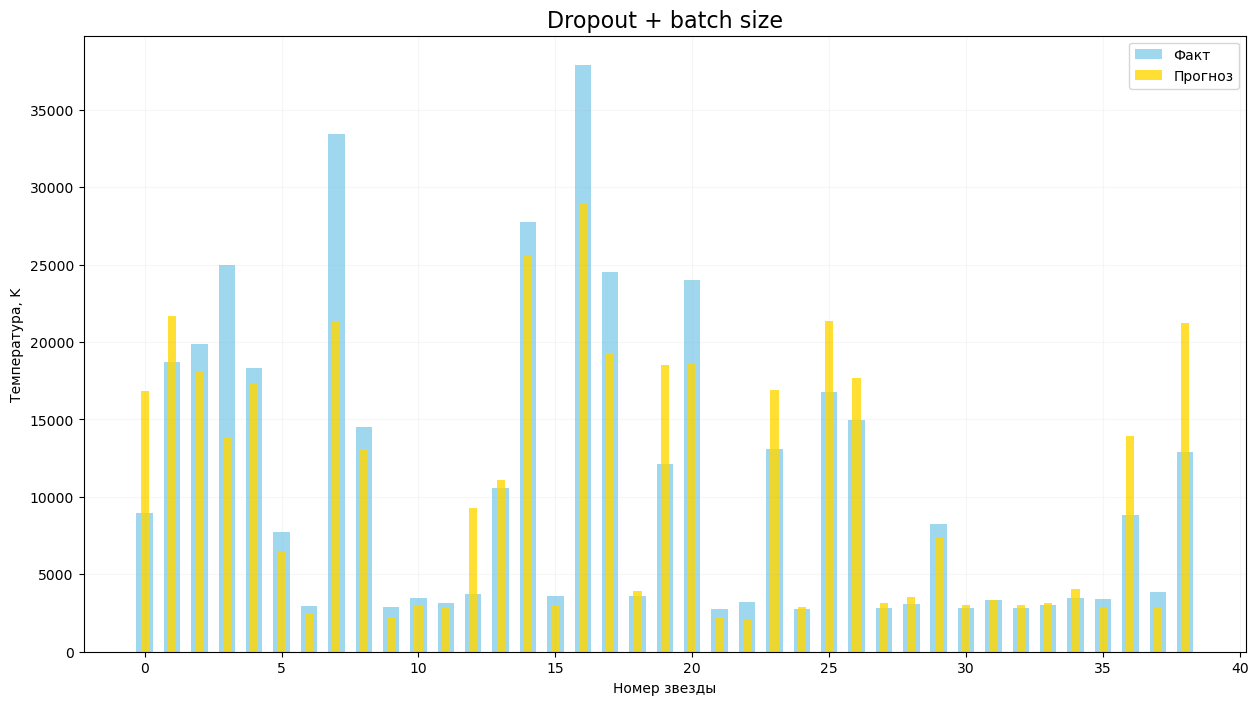

In [45]:
best_dropout_model = best_dropout_result['model']

best_dropout_model.eval()

with torch.no_grad():
    val_predictions_dropout = best_dropout_model(X_val).flatten()

fact_prediction(val_predictions_dropout, y_val, 'Dropout + batch size')

Перебор `batch_size` и `dropout` не позволил улучшить baseline. Поэтому в качестве итоговой модели сохраняется baseline [8,4] + `ELU`, обученная full-batch без Dropout.

**Выводы**

Лучший результат на валидационной выборке показала архитектура с двумя скрытыми слоями [8, 4] и функцией активации `ELU`: `RMSE = 4127.45 K`.

Далее использовался `Batch Normalization`, проведён перебор размеров батча и вероятности `Dropout` при неизменной архитектуре. Дополнительная регуляризация не улучшила качество.

### Оценка качества и анализ ошибок 

In [46]:
final_model = best_arch_model

final_model.eval()

with torch.no_grad():
    test_predictions = final_model(X_test).flatten()

    test_rmse = torch.sqrt(
        nn.MSELoss()(
            test_predictions,
            y_test
        )
    ).item()

print(f'Test RMSE: {test_rmse:.2f} K')

Test RMSE: 4360.16 K


На тестовой выборке итоговая модель получила `RMSE = 4360.16 K`, что удовлетворяет условию задания RMSE < 4500 K.

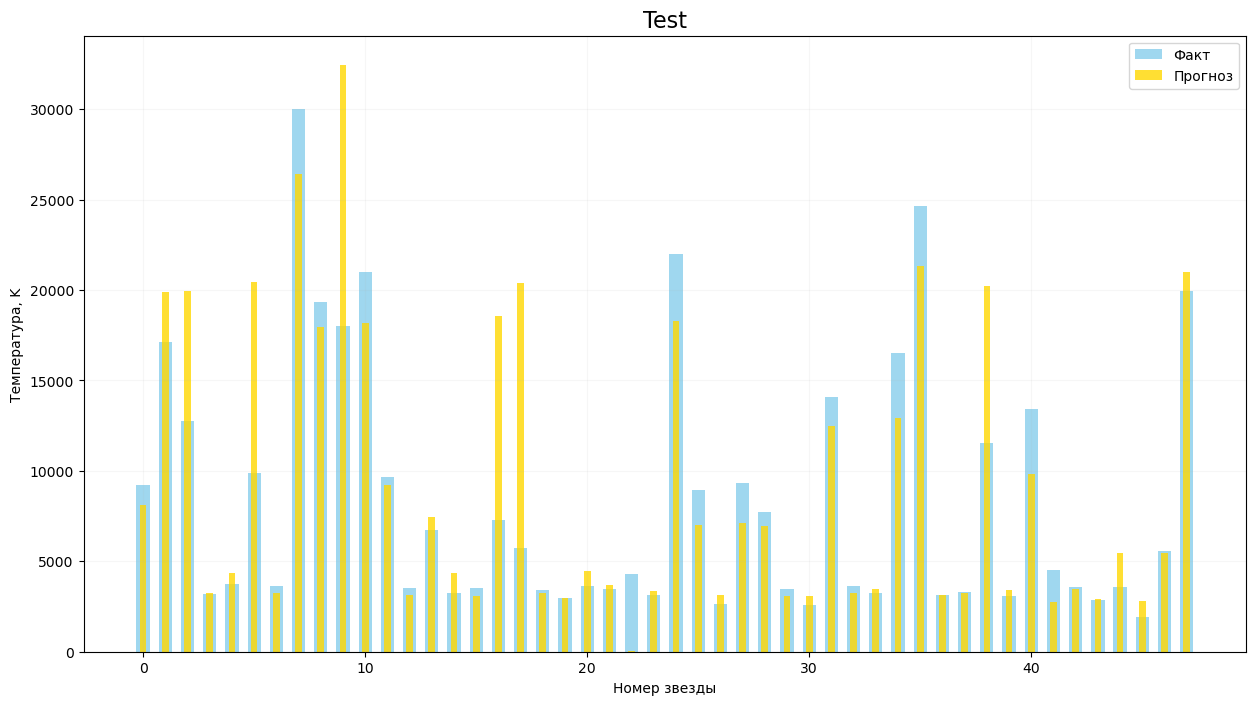

In [47]:
fact_prediction(test_predictions, y_test,'Test')

Видно, что большинство звёзд с относительно низкими температурами прогнозируются достаточно близко к фактическим значениям. Однако на отдельных объектах наблюдаются очень большие расхождения между фактом и прогнозом.

Так как `RMSE` рассчитывается на основе квадратов ошибок, небольшое число таких отклонений может оказывать существенное влияние на итоговую метрику. Следовательно, выполнение целевого значения `RMSE` не гарантирует одинаково высокую точность прогнозирования для всех групп звёзд.

Для более подробной оценки качества проанализируем ошибки в зависимости от типа звезды (`Star type`). Рассчитаем для каждой группы `MAE`, `RMSE` и среднюю ошибку со знаком (`mean_error`), чтобы определить величину отклонений и выявить возможные систематические завышения или занижения температуры.

In [48]:
star_type_name = {
    0: 'Коричневый карлик',
    1: 'Красный карлик',
    2: 'Белый карлик',
    3: 'Звезда главной последовательности',
    4: 'Сверхгигант',
    5: 'Гипергигант'
}

test_results = pd.DataFrame({
    'true_temperature': y_test.numpy(),
    'pred_temperature': test_predictions.numpy(),
    'star_type': X_test_raw['Star type'].to_numpy(),
    'star_color': X_test_raw['Star color'].to_numpy()
})

test_results['star_type_name'] = test_results['star_type'].map(star_type_name)
test_results['error'] = test_results['pred_temperature'] - test_results['true_temperature']
test_results['abs_error'] = test_results['error'].abs()
test_results['sq_error'] = (test_results['error'] ** 2)

In [49]:
errors = (test_results.groupby(['star_type','star_type_name'])
    .agg(
        n=('true_temperature','size'),
        MAE=('abs_error', 'mean'),
        RMSE=('sq_error', lambda x: np.sqrt(x.mean())),
        mean_error=('error','mean')
    ).reset_index())

errors

,star_type,star_type_name,n,MAE,RMSE,mean_error
0,0,Коричневый карлик,7,317.945557,435.921783,206.628799
1,1,Красный карлик,8,228.962189,267.622681,-29.657501
2,2,Белый карлик,8,2020.716553,2311.659912,-2020.716553
3,3,Звезда главной последовательности,6,2016.539062,2416.935059,-1787.442993
4,4,Сверхгигант,10,6239.891602,7767.463867,5585.314453
5,5,Гипергигант,9,2491.124023,5049.655762,1083.836426


Анализ ошибок показал, что качество модели неоднородно для разных типов звёзд. Наиболее точные прогнозы получены для коричневых и красных карликах, тогда как наибольшие ошибки наблюдаются для сверхгигантов и гипергигантов.

Для белых карликов и звёзд главной последовательности наблюдается преимущественное занижение температуры. Для сверхгигантов характерно выраженное завышение температуры. 

Датасет содержит всего 240 объектов, поэтому итоговая метрика чувствительна к конкретному разбиению данных. Поэтому значение 4360.16 K следует интерпретировать как качество модели на данном тестовом разбиении, а не как точную оценку качества на произвольной новой выборке.

## Выводы

В ходе работы была построена и исследована нейронная сеть для прогнозирования температуры поверхности звёзд по их характеристикам.

* **Загрузка и исследовательский анализ данных**

Для моделирования использован датасет, содержащий информацию о 240 звёздах. Целевой переменной являлась температура поверхности звезды в Кельвинах (`Temperature (K)`).

Проведены исследовательский анализ данных, проверка на пропуски и дубликаты, изучены распределения числовых и категориальных признаков. Корреляционный анализ позволил выявить связи между характеристиками звёзд и целевой переменной.

Установлено, что температура, светимость, радиус и абсолютная звёздная величина имеют широкие диапазоны значений, а отдельные категории звёзд существенно различаются по своим характеристикам.

* **Предобработка и подготовка данных**

Устранены различия в написании категорий признака `Star color`, объединены некоторые крайне редкие близкие категории. Признаки `Star type` и `Star color` закодированы методом One-Hot Encoding, числовые признаки стандартизированы с помощью `StandardScaler`.

Данные разделены на обучающую (153 объекта), валидационную (39 объектов) и тестовую (48 объектов) выборки. Преобразования признаков обучались исключительно на обучающей выборке, чтобы исключить утечку информации.

* **Построение базовой нейронной сети**

Разработана полносвязная нейронная сеть с двумя скрытыми слоями и одним выходным нейроном с линейной активацией. Для обучения использовался оптимизатор Adam, а в качестве функции потерь - MSE. Основной метрикой оценки качества выбрана RMSE.

Проведён экспериментальный подбор числа нейронов на скрытых слоях и функций активации `ReLU`, `ELU` и `LeakyReLU`.

Лучший результат на валидационной выборке показала архитектура **[8, 4] с функцией активации ELU**:

- Исходная архитектура [8, 4] + ReLU: RMSE = 4883.41 K.
- Выбранная архитектура [8, 4] + ELU: RMSE = 4127.45 K.

Таким образом, подбор функции активации позволил снизить валидационную ошибку на 755.96 K (около 15.5%).

* **Эксперименты по улучшению модели**

Для выбранной архитектуры проведены эксперименты с Batch Normalization, Dropout и различными размерами батча.

Использование Batch Normalization не улучшило качество модели: RMSE увеличился до 7142.47 K.

Перебор значений Dropout и размеров батча также не позволил превзойти исходную модель. Лучший результат mini-batch обучения составил 4263.19 K при размере батча 8 и `dropout = 0`. При увеличении вероятности Dropout качество в целом ухудшалось.

Поэтому в качестве итоговой сохранена архитектура **[8, 4] + ELU без Batch Normalization и Dropout**, обученная на полной обучающей выборке за одну эпоху (full-batch).

* **Оценка качества и анализ ошибок**

Итоговая модель показала на тестовой выборке: **RMSE = 4360.16 K**, что удовлетворяет установленному в задании критерию RMSE ≤ 4500 K.

Однако дополнительный анализ выявил существенную неоднородность ошибок в зависимости от типа звезды.

Наиболее точные прогнозы получены для красных и коричневых карликов: RMSE составил 267.62 K и 435.92 K соответственно. Для сверхгигантов и гипергигантов ошибки значительно выше - 7767.46 K и 5049.66 K. 

* **Ограничения и возможные направления дальнейшей работы**

Основным ограничением исследования является небольшой объём датасета - всего 240 объектов. При таком количестве наблюдений качество модели существенно зависит от состава обучающей и тестовой выборок.

Для дальнейшего улучшения модели целесообразно расширить датасет, прежде всего за счёт объектов с высокими температурами и недостаточно представленными сочетаниями характеристик, а также повторно оценить устойчивость результатов на независимых данных.

**Итог**

Основная цель работы достигнута: разработана и обучена нейронная сеть для прогнозирования температуры поверхности звёзд. На выбранной тестовой выборке модель выполнила установленный критерий качества - RMSE составил 4360.16 K.

При этом эксперименты показали, что увеличение сложности сети и применение дополнительных методов регуляризации не обязательно улучшают прогнозирование. В рассматриваемой задаче наилучший результат среди проверенных конфигураций показала компактная архитектура [8, 4] + ELU.

Анализ ошибок и кросс-валидация выявили ограничения модели, связанные с небольшим объёмом данных и различиями в распределении характеристик отдельных групп звёзд. Поэтому полученное решение следует рассматривать как исследовательский прототип, требующий дополнительной проверки перед практическим применением.